In [1]:
import os, json, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running inside Colab - assuming the Drive folders already exist locally.")


BASE        = "/content/drive/MyDrive"
FROZEN_DIR  = f"{BASE}/frozen_dataset"
FEATURE_DIR = f"{BASE}/feature_engineering_v1"
TRAIN_PATH  = f"{FROZEN_DIR}/dataset_v1_train.csv"
TEST_PATH   = f"{FROZEN_DIR}/dataset_v1_test.csv"
FULL_PATH   = f"{FROZEN_DIR}/dataset_v1_full.csv"
ENGINEERED_PATH = f"{FEATURE_DIR}/engineered_dataset.csv"

OUT_DIR = f"{BASE}/day21/best_candidate_review"
os.makedirs(OUT_DIR, exist_ok=True)

TARGET        = "soc_percent"
RAW_FEATURES  = ["voltage_v", "current_a", "cell_temp_c", "power_w", "ambient_temp_c"]
CHARGE_TARGET = "remaining_charge_time_s"
CHARGE_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "ambient_temp_c"]
SEED = 42

for p in [TRAIN_PATH, TEST_PATH]:
    assert os.path.exists(p), f"Couldn't find {p} - check the Day 12 frozen_dataset copy step."

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

missing = [c for c in RAW_FEATURES + [TARGET, "file_id"] if c not in df_train.columns]
assert not missing, f"Missing columns in train file: {missing}"
train_ids, test_ids = df_train["file_id"].unique(), df_test["file_id"].unique()
assert set(train_ids).isdisjoint(test_ids), "Train/test share file_ids - the frozen split is broken!"

X_train, y_train = df_train[RAW_FEATURES], df_train[TARGET]
X_test,  y_test  = df_test[RAW_FEATURES],  df_test[TARGET]

print(f"Frozen split  -> train {df_train.shape} ({len(train_ids)} files) | test {df_test.shape} ({len(test_ids)} files)")
print("Train/test files are disjoint: OK (split is grouped by file_id)")
print("Ambient temperatures in train:", sorted(df_train['ambient_temp_c'].round().unique()))
print("Ambient temperatures in test :", sorted(df_test['ambient_temp_c'].round().unique()))

Mounted at /content/drive
Frozen split  -> train (5028, 7) (18 files) | test (328, 7) (5 files)
Train/test files are disjoint: OK (split is grouped by file_id)
Ambient temperatures in train: [np.int64(25)]
Ambient temperatures in test : [np.int64(25)]


In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, ParameterGrid
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

def metrics(y_true, y_pred):
    return {"MAE": float(mean_absolute_error(y_true, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": float(r2_score(y_true, y_pred))}


gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_idx, val_idx = next(gss.split(df_train, groups=df_train["file_id"]))
df_fit, df_val = df_train.iloc[tr_idx], df_train.iloc[val_idx]
X_fit, y_fit = df_fit[RAW_FEATURES], df_fit[TARGET]
X_val, y_val = df_val[RAW_FEATURES], df_val[TARGET]
print(f"Validation carve-out -> fit {X_fit.shape}, val {X_val.shape}")

param_grid = {"n_estimators": [150, 300], "max_depth": [8, 12], "min_samples_leaf": [2, 4]}   # Day 20 grid
log = []
for params in ParameterGrid(param_grid):
    m = RandomForestRegressor(random_state=SEED, n_jobs=-1, **params).fit(X_fit, y_fit)
    mt = metrics(y_val, m.predict(X_val))
    log.append({**params, "val_MAE": mt["MAE"], "val_RMSE": mt["RMSE"], "val_R2": mt["R2"]})
    print(f"  {params} -> val_MAE={mt['MAE']:.4f}  val_RMSE={mt['RMSE']:.4f}")

tuning_log = pd.DataFrame(log).sort_values("val_MAE").reset_index(drop=True)
best_params = {k: int(tuning_log.loc[0, k]) for k in param_grid}
print("\nBest validated Random-Forest config:", best_params)
display(tuning_log)
tuning_log.to_csv(f"{OUT_DIR}/rf_tuning_log.csv", index=False)

Validation carve-out -> fit (4840, 5), val (188, 5)
  {'max_depth': 8, 'min_samples_leaf': 2, 'n_estimators': 150} -> val_MAE=11.3954  val_RMSE=18.9217
  {'max_depth': 8, 'min_samples_leaf': 2, 'n_estimators': 300} -> val_MAE=11.3774  val_RMSE=18.9484
  {'max_depth': 8, 'min_samples_leaf': 4, 'n_estimators': 150} -> val_MAE=12.9478  val_RMSE=21.2853
  {'max_depth': 8, 'min_samples_leaf': 4, 'n_estimators': 300} -> val_MAE=13.1191  val_RMSE=21.3892
  {'max_depth': 12, 'min_samples_leaf': 2, 'n_estimators': 150} -> val_MAE=10.9868  val_RMSE=18.6101
  {'max_depth': 12, 'min_samples_leaf': 2, 'n_estimators': 300} -> val_MAE=10.9824  val_RMSE=18.5990
  {'max_depth': 12, 'min_samples_leaf': 4, 'n_estimators': 150} -> val_MAE=12.7389  val_RMSE=21.1510
  {'max_depth': 12, 'min_samples_leaf': 4, 'n_estimators': 300} -> val_MAE=12.8786  val_RMSE=21.2418

Best validated Random-Forest config: {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 2}


,max_depth,min_samples_leaf,n_estimators,val_MAE,val_RMSE,val_R2
0,12,2,300,10.982358,18.599035,0.661335
1,12,2,150,10.986757,18.610096,0.660932
2,8,2,300,11.377435,18.948434,0.648491
3,8,2,150,11.395369,18.921712,0.649482
4,12,4,150,12.738872,21.150980,0.562024
5,12,4,300,12.878640,21.241766,0.558256
6,8,4,150,12.947779,21.285331,0.556442
7,8,4,300,13.119140,21.389240,0.552101


===== SOC - BASELINE vs TUNED (test set) =====


,train_MAE,test_MAE,test_RMSE,test_R2,MAE_gap,verdict,MAE_gain_vs_mean_%,RMSE/MAE
model,,,,,,,,
Mean baseline,27.2882,28.9281,32.1916,-0.0328,1.6399,underfit / reference,0.0000,1.1128
Linear (raw),6.3538,18.5536,25.1951,0.3673,12.1999,train-test gap >50% (flag),35.8629,1.3580
RF untuned (Day 16),0.8591,27.3297,37.7166,-0.4178,26.4707,train-test gap >50% (flag),5.5254,1.3801
RF tuned,0.9344,27.4126,37.8479,-0.4276,26.4783,train-test gap >50% (flag),5.2387,1.3807
Gradient Boosting (raw),1.6073,25.8461,36.9800,-0.3629,24.2388,train-test gap >50% (flag),10.6540,1.4308



Lowest test MAE : Linear (raw)
Lowest test RMSE: Linear (raw)


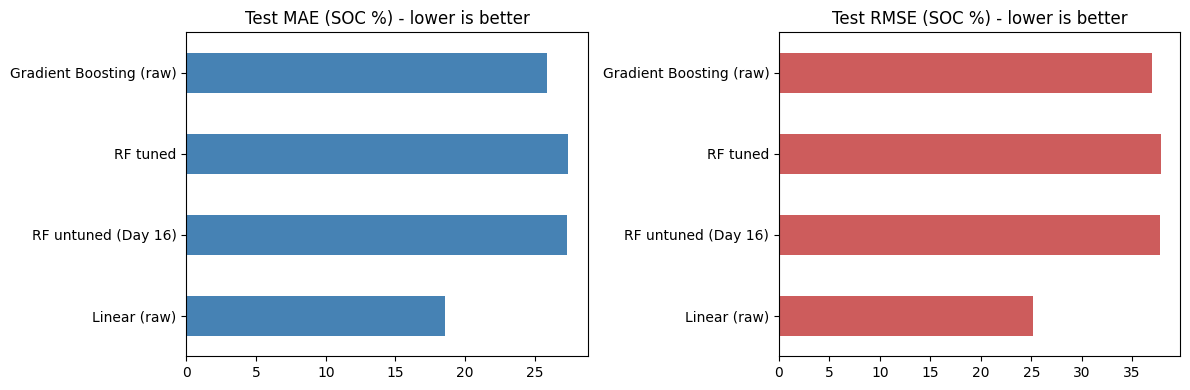

In [3]:
M_MEAN, M_LIN, M_RFU, M_RFT, M_GB = ("Mean baseline", "Linear (raw)", "RF untuned (Day 16)",
                                      "RF tuned", "Gradient Boosting (raw)")
models = {
    M_MEAN: DummyRegressor(strategy="mean"),
    M_LIN:  LinearRegression(),
    M_RFU:  RandomForestRegressor(n_estimators=300, max_depth=14, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    M_RFT:  RandomForestRegressor(random_state=SEED, n_jobs=-1, **best_params),
    M_GB:   HistGradientBoostingRegressor(max_iter=300, max_depth=6, learning_rate=0.05, random_state=SEED),
}
pred_tr, pred_te, fitted = {}, {}, {}
for name, m in models.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    pred_tr[name], pred_te[name] = m.predict(X_train), m.predict(X_test)

def verdict(tr, te):
    if tr["R2"] < 0.60:                    return "underfit / reference"
    if te["MAE"] - tr["MAE"] > 0.5*tr["MAE"]: return "train-test gap >50% (flag)"
    return "ok"

rows = []
for name in models:
    tr, te = metrics(y_train, pred_tr[name]), metrics(y_test, pred_te[name])
    rows.append({"model": name, "train_MAE": tr["MAE"], "test_MAE": te["MAE"], "test_RMSE": te["RMSE"],
                 "test_R2": te["R2"], "MAE_gap": te["MAE"] - tr["MAE"], "verdict": verdict(tr, te)})
results = pd.DataFrame(rows).set_index("model")
mean_mae = results.loc[M_MEAN, "test_MAE"]
results["MAE_gain_vs_mean_%"] = 100 * (mean_mae - results["test_MAE"]) / mean_mae
results["RMSE/MAE"] = results["test_RMSE"] / results["test_MAE"]
print("===== SOC - BASELINE vs TUNED (test set) =====")
display(results.round(4))
results.to_csv(f"{OUT_DIR}/soc_baseline_vs_tuned.csv")

best_mae_model  = results.drop(M_MEAN)["test_MAE"].idxmin()
best_rmse_model = results.drop(M_MEAN)["test_RMSE"].idxmin()
print(f"\nLowest test MAE : {best_mae_model}")
print(f"Lowest test RMSE: {best_rmse_model}")
if best_mae_model != best_rmse_model:
    print("-> The two metrics disagree. A model with slightly lower MAE but a much larger RMSE makes\n"
          "   occasional BIG mistakes. That is exactly what Section 6-8 investigate.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
r = results.drop(M_MEAN)
r["test_MAE"].plot(kind="barh", ax=ax[0], color="steelblue");  ax[0].set_title("Test MAE (SOC %) - lower is better")
r["test_RMSE"].plot(kind="barh", ax=ax[1], color="indianred"); ax[1].set_title("Test RMSE (SOC %) - lower is better")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_baseline_vs_tuned.png", dpi=150); plt.show()

In [4]:
HAVE_ENG = os.path.exists(ENGINEERED_PATH)
eng_summary = {}
if not HAVE_ENG:
    print("engineered_dataset.csv not found - skipping (copy Day 13 feature_engineering_v1/ to Drive).")
else:
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from scipy.stats import ks_2samp

    df_eng = pd.read_csv(ENGINEERED_PATH)
    eng_cols = [c for c in df_eng.select_dtypes("number").columns if c not in ["timestamp", TARGET]]
    df_eng[eng_cols] = df_eng[eng_cols].replace([np.inf, -np.inf], np.nan)
    e_tr = df_eng[df_eng["file_id"].isin(train_ids)]
    e_te = df_eng[df_eng["file_id"].isin(test_ids)]
    print(f"Engineered features ({len(eng_cols)}): {eng_cols}")
    print(f"NaN/inf cells -> train {int(e_tr[eng_cols].isna().sum().sum())}, test {int(e_te[eng_cols].isna().sum().sum())}")

    for label, est in [("Linear (engineered)", LinearRegression()),
                       ("RF quick (engineered)", RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=4,
                                                                         random_state=SEED, n_jobs=-1))]:
        pipe = make_pipeline(SimpleImputer(strategy="median"), est).fit(e_tr[eng_cols], e_tr[TARGET])
        mt = metrics(e_te[TARGET], pipe.predict(e_te[eng_cols]))
        eng_summary[label] = mt
        print(f"  {label:24s} test MAE={mt['MAE']:.3f}  RMSE={mt['RMSE']:.3f}  R2={mt['R2']:.4f}")

    rows = []
    for c in eng_cols:
        a, b = e_tr[c].dropna(), e_te[c].dropna()
        rows.append({"feature": c,
                     "corr_train": e_tr[c].corr(e_tr[TARGET]), "corr_test": e_te[c].corr(e_te[TARGET]),
                     "KS_train_vs_test": ks_2samp(a, b).statistic if len(a) and len(b) else np.nan,
                     "NaN_%": 100 * df_eng[c].isna().mean()})
    eng_diag = pd.DataFrame(rows).set_index("feature")
    eng_diag["corr_sign_flip"] = np.sign(eng_diag["corr_train"]) != np.sign(eng_diag["corr_test"])
    print("\nPer-feature diagnostics (a sign flip or large KS means the feature behaves differently on unseen files):")
    display(eng_diag.sort_values("KS_train_vs_test", ascending=False).round(3))
    eng_diag.to_csv(f"{OUT_DIR}/engineered_feature_diagnostics.csv")
    n_flip = int(eng_diag["corr_sign_flip"].sum())
    print(f"\nFeatures whose correlation with SOC flips sign train->test: {n_flip}")
    print("Likely causes to check in Week 4: per-file cumulative features (e.g. coulomb counting) that start from an unknown SOC,\n"
          "rolling/lag features computed across file boundaries, or features that encode file identity rather than physics.")

engineered_dataset.csv not found - skipping (copy Day 13 feature_engineering_v1/ to Drive).



===== ERROR BY SOC BAND =====


,n_rows,MAE_RF,MAE_Linear,RMSE_RF,RMSE_Linear
SOC_band,,,,,
0-15 (knee),25,71.640,15.691,74.437,19.037
15-30,36,61.286,27.592,62.761,27.785
30-50,47,47.796,22.766,48.514,22.955
50-70,48,31.397,14.766,31.841,14.846
70-85,36,20.292,9.808,20.638,9.968
85-100,136,3.751,18.884,10.469,31.206



===== ERROR BY AMBIENT TEMPERATURE (DEG C) =====


,n_rows,MAE_RF,MAE_Linear,RMSE_RF,RMSE_Linear
Ambient_C,,,,,
25,328,27.413,18.554,37.848,25.195



===== ERROR BY CURRENT QUINTILE =====


,n_rows,MAE_RF,MAE_Linear,RMSE_RF,RMSE_Linear
Current_quintile,,,,,
"(-0.151, 0.0]",65,11.516,29.534,29.266,42.122
"(-0.154, -0.151]",110,35.995,15.019,42.390,16.767
"(0.0, 0.148]",111,33.135,15.598,41.069,18.765
"(0.148, 3.001]",42,14.413,18.629,26.414,23.338


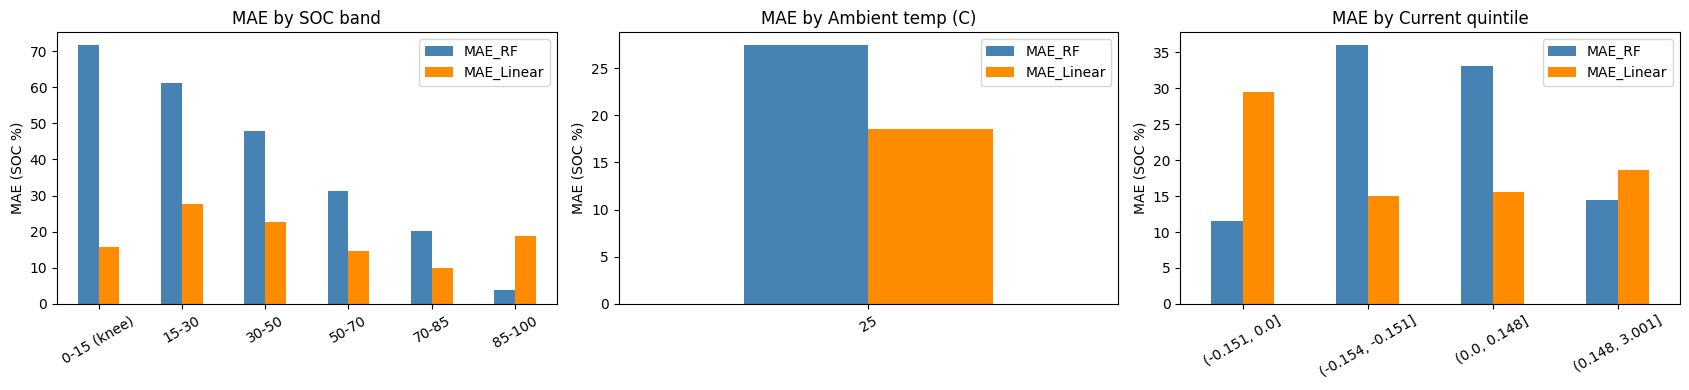

Worst SOC band for RF: 0-15 (knee)  (MAE 71.64)
Worst ambient temp for RF: 25 C  (MAE 27.41)

===== INPUTS OUTSIDE THE TRAINING 1-99 PERCENTILE RANGE? =====


,MAE_RF,MAE_Linear,n_rows
outside_train_range,,,
False,26.474,18.426,302
True,38.320,20.031,26


Trees predict flat values outside the range they saw; a linear model extrapolates. A big RF gap on the 'True' row supports that explanation.


In [5]:
ev = df_test[["file_id", "ambient_temp_c", "current_a", TARGET]].copy().reset_index(drop=True)
ev["pred_rf"]  = pred_te[M_RFT]
ev["pred_lin"] = pred_te[M_LIN]
for k in ["rf", "lin"]:
    ev[f"err_{k}"] = ev[TARGET] - ev[f"pred_{k}"]
    ev[f"abs_{k}"] = ev[f"err_{k}"].abs()
    ev[f"sq_{k}"]  = ev[f"err_{k}"] ** 2

ev["SOC_band"]  = pd.cut(ev[TARGET], [-0.01, 15, 30, 50, 70, 85, 100.01],
                         labels=["0-15 (knee)", "15-30", "30-50", "50-70", "70-85", "85-100"])
ev["Ambient_C"] = ev["ambient_temp_c"].round().astype(int)
ev["Current_quintile"] = pd.qcut(ev["current_a"], 5, duplicates="drop").astype(str)

def breakdown(key):
    g = ev.groupby(key, observed=True)
    return pd.DataFrame({"n_rows": g.size(),
                         "MAE_RF": g["abs_rf"].mean(),  "MAE_Linear": g["abs_lin"].mean(),
                         "RMSE_RF": np.sqrt(g["sq_rf"].mean()), "RMSE_Linear": np.sqrt(g["sq_lin"].mean())})

by_soc, by_temp, by_cur = breakdown("SOC_band"), breakdown("Ambient_C"), breakdown("Current_quintile")
for title, t in [("SOC band", by_soc), ("Ambient temperature (deg C)", by_temp), ("Current quintile", by_cur)]:
    print(f"\n===== ERROR BY {title.upper()} =====")
    display(t.round(3))
by_soc.to_csv(f"{OUT_DIR}/error_by_soc_band.csv"); by_temp.to_csv(f"{OUT_DIR}/error_by_ambient_temp.csv")
by_cur.to_csv(f"{OUT_DIR}/error_by_current_quintile.csv")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (t, ttl) in zip(ax, [(by_soc, "SOC band"), (by_temp, "Ambient temp (C)"), (by_cur, "Current quintile")]):
    t[["MAE_RF", "MAE_Linear"]].plot(kind="bar", ax=a, color=["steelblue", "darkorange"])
    a.set_title(f"MAE by {ttl}"); a.set_ylabel("MAE (SOC %)"); a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_error_by_regime.png", dpi=150); plt.show()

worst_soc_band = by_soc["MAE_RF"].idxmax();  worst_temp = by_temp["MAE_RF"].idxmax()
print(f"Worst SOC band for RF: {worst_soc_band}  (MAE {by_soc['MAE_RF'].max():.2f})")
print(f"Worst ambient temp for RF: {worst_temp} C  (MAE {by_temp['MAE_RF'].max():.2f})")

# ---- out-of-distribution check: do trees fail where test inputs leave the training range? ----
lo, hi = X_train.quantile(0.01), X_train.quantile(0.99)
ood = ((X_test < lo) | (X_test > hi)).any(axis=1).values
ev["outside_train_range"] = ood
ood_tab = ev.groupby("outside_train_range")[["abs_rf", "abs_lin"]].mean().rename(columns={"abs_rf": "MAE_RF", "abs_lin": "MAE_Linear"})
ood_tab["n_rows"] = ev.groupby("outside_train_range").size()
print("\n===== INPUTS OUTSIDE THE TRAINING 1-99 PERCENTILE RANGE? =====")
display(ood_tab.round(3))
print("Trees predict flat values outside the range they saw; a linear model extrapolates. A big RF gap on the 'True' row supports that explanation.")
ood_tab.to_csv(f"{OUT_DIR}/error_vs_input_range.csv")

===== PER-FILE MAE (tuned RF vs Linear), best -> worst =====


,n_rows,ambient_C,MAE_RF,MAE_Linear,max_abs_err_RF
file_id,,,,,
25degC_Charge6,21,25,0.959,28.667,12.102
25degC_Charge15,21,25,2.803,28.283,41.178
25degC_Charge14,21,25,3.310,28.614,36.257
25degC_Charge8,22,25,6.345,27.999,86.338
25degC_C20DisCh,243,25,35.816,15.114,92.691


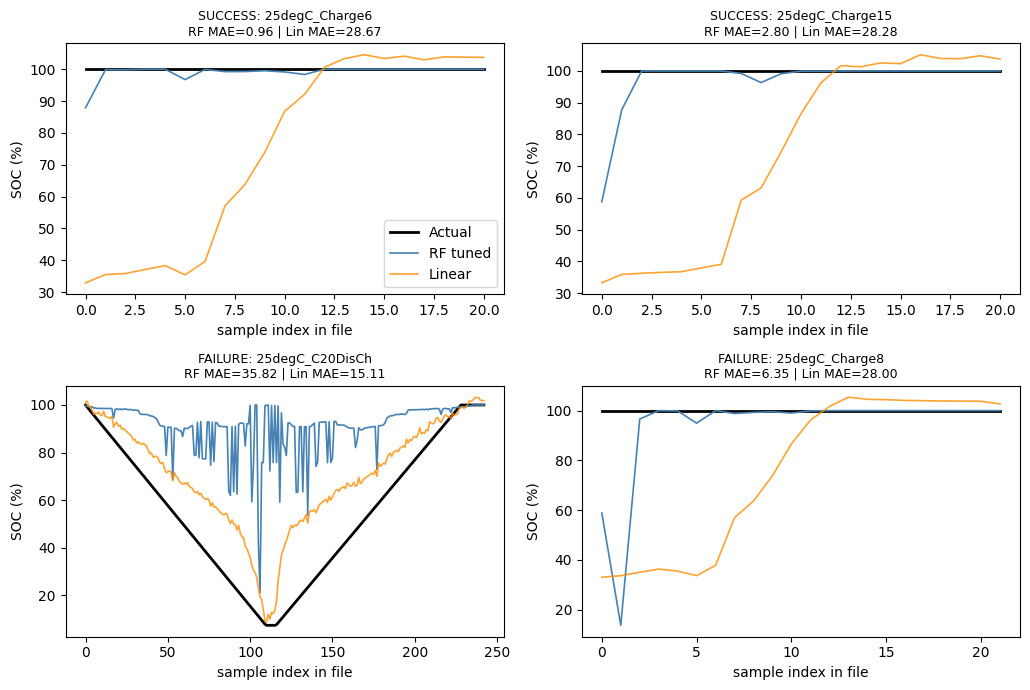

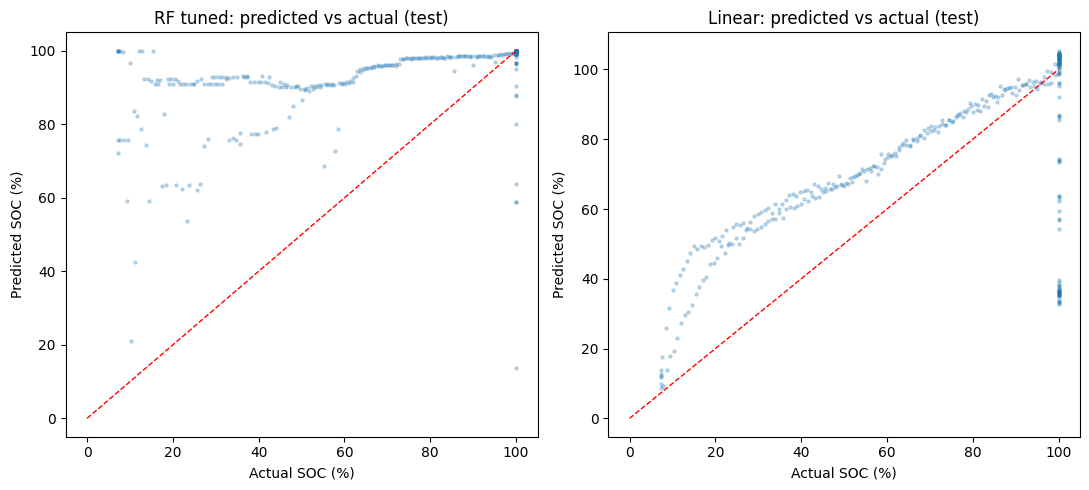

Success files: ['25degC_Charge6', '25degC_Charge15']
Failure files: ['25degC_C20DisCh', '25degC_Charge8']


In [6]:
pf = ev.groupby("file_id").agg(n_rows=("abs_rf", "size"), ambient_C=("Ambient_C", "first"),
                               MAE_RF=("abs_rf", "mean"), MAE_Linear=("abs_lin", "mean"),
                               max_abs_err_RF=("abs_rf", "max")).sort_values("MAE_RF")
print("===== PER-FILE MAE (tuned RF vs Linear), best -> worst =====")
display(pf.round(3))
pf.to_csv(f"{OUT_DIR}/per_file_errors.csv")

k = min(3, max(1, len(pf) // 2))
best_files, worst_files = list(pf.index[:k]), list(pf.index[-k:][::-1])
fig, axes = plt.subplots(2, k, figsize=(5.2 * k, 7), squeeze=False)
for row, (files, tag) in enumerate([(best_files, "SUCCESS"), (worst_files, "FAILURE")]):
    for col, f in enumerate(files):
        d = ev[ev["file_id"] == f].reset_index(drop=True)
        a = axes[row, col]
        a.plot(d[TARGET].values, label="Actual", lw=2, color="black")
        a.plot(d["pred_rf"].values, label="RF tuned", lw=1.2, color="steelblue")
        a.plot(d["pred_lin"].values, label="Linear", lw=1.2, color="darkorange", alpha=.8)
        a.set_title(f"{tag}: {f}\nRF MAE={pf.loc[f,'MAE_RF']:.2f} | Lin MAE={pf.loc[f,'MAE_Linear']:.2f}", fontsize=9)
        a.set_xlabel("sample index in file"); a.set_ylabel("SOC (%)")
        if row == 0 and col == 0: a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_success_failure_traces.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, key, ttl in [(ax[0], "pred_rf", "RF tuned"), (ax[1], "pred_lin", "Linear")]:
    a.scatter(ev[TARGET], ev[key], s=5, alpha=.25)
    a.plot([0, 100], [0, 100], "r--", lw=1)
    a.set_xlabel("Actual SOC (%)"); a.set_ylabel("Predicted SOC (%)"); a.set_title(f"{ttl}: predicted vs actual (test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_pred_vs_actual.png", dpi=150); plt.show()

print("Success files:", best_files)
print("Failure files:", worst_files)

RF median |error| = 24.02, 95th pct = 74.78, 99th pct = 92.36, max = 92.69 (SOC %)
Top 1% of rows account for 5.5% of RF's total squared error
Single worst file (25degC_C20DisCh) accounts for 97.2% of RF's total squared error

===== 15 LARGEST RF MISTAKES =====


,file_id,ambient_temp_c,current_a,soc_percent,pred_rf,pred_lin,err_rf
111,25degC_C20DisCh,25,0.000,7.309,100.000,11.900,-92.691
110,25degC_C20DisCh,25,0.000,7.309,99.798,8.730,-92.489
113,25degC_C20DisCh,25,0.000,7.309,99.798,12.704,-92.489
115,25degC_C20DisCh,25,0.000,7.309,99.798,13.727,-92.489
109,25degC_C20DisCh,25,-0.153,7.780,99.798,9.286,-92.018
117,25degC_C20DisCh,25,0.148,8.381,99.591,26.003,-91.210
104,25degC_C20DisCh,25,-0.153,12.007,100.000,27.443,-87.993
103,25degC_C20DisCh,25,-0.151,12.852,100.000,29.560,-87.148
119,25degC_C20DisCh,25,0.148,10.031,96.661,36.698,-86.630
265,25degC_Charge8,25,0.000,100.000,13.662,33.604,86.338



RF predictions outside [0, 100]: 0 rows
Effect of clipping predictions to [0, 100] (free post-processing):


,MAE,RMSE,R2
Linear (raw),18.1044,25.1635,0.3689
RF tuned,27.4126,37.8479,-0.4276
Gradient Boosting (raw),25.4238,36.6055,-0.3355


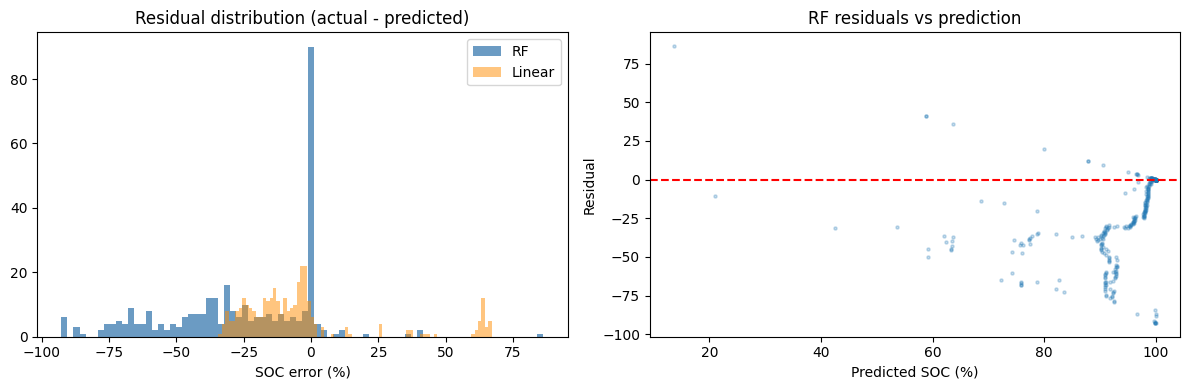

In [7]:
n = len(ev)
sse_total = ev["sq_rf"].sum()
top1_share = ev["sq_rf"].nlargest(max(1, int(0.01 * n))).sum() / sse_total
worst_file = ev.groupby("file_id")["sq_rf"].sum().idxmax()
worst_file_share = ev.groupby("file_id")["sq_rf"].sum().max() / sse_total
p95, p99 = ev["abs_rf"].quantile(.95), ev["abs_rf"].quantile(.99)
print(f"RF median |error| = {ev['abs_rf'].median():.2f}, 95th pct = {p95:.2f}, 99th pct = {p99:.2f}, max = {ev['abs_rf'].max():.2f} (SOC %)")
print(f"Top 1% of rows account for {100*top1_share:.1f}% of RF's total squared error")
print(f"Single worst file ({worst_file}) accounts for {100*worst_file_share:.1f}% of RF's total squared error")

print("\n===== 15 LARGEST RF MISTAKES =====")
cols = ["file_id", "ambient_temp_c", "current_a", TARGET, "pred_rf", "pred_lin", "err_rf"]
display(ev.loc[ev["abs_rf"].nlargest(15).index, cols].round(3))
ev.loc[ev["abs_rf"].nlargest(200).index, cols].to_csv(f"{OUT_DIR}/largest_200_errors.csv", index=False)


imp = int(((ev["pred_rf"] < 0) | (ev["pred_rf"] > 100)).sum())
clip_metrics = {name: metrics(y_test, np.clip(pred_te[name], 0, 100)) for name in [M_LIN, M_RFT, M_GB]}
print(f"\nRF predictions outside [0, 100]: {imp} rows")
print("Effect of clipping predictions to [0, 100] (free post-processing):")
display(pd.DataFrame(clip_metrics).T.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(ev["err_rf"], bins=80, color="steelblue", alpha=.8, label="RF")
ax[0].hist(ev["err_lin"], bins=80, color="darkorange", alpha=.5, label="Linear")
ax[0].set_title("Residual distribution (actual - predicted)"); ax[0].set_xlabel("SOC error (%)"); ax[0].legend()
ax[1].scatter(ev["pred_rf"], ev["err_rf"], s=5, alpha=.25); ax[1].axhline(0, color="r", ls="--")
ax[1].set_title("RF residuals vs prediction"); ax[1].set_xlabel("Predicted SOC (%)"); ax[1].set_ylabel("Residual")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_residuals.png", dpi=150); plt.show()

In [8]:
lin_v = LinearRegression().fit(X_fit, y_fit)
rf_v  = RandomForestRegressor(random_state=SEED, n_jobs=-1, **best_params).fit(X_fit, y_fit)
res_rf = RandomForestRegressor(n_estimators=150, max_depth=8, min_samples_leaf=4, random_state=SEED, n_jobs=-1)
res_rf.fit(X_fit, y_fit - lin_v.predict(X_fit))

probe = pd.DataFrame({
    "Linear":              metrics(y_val, lin_v.predict(X_val)),
    "RF tuned":            metrics(y_val, rf_v.predict(X_val)),
    "Hybrid (Linear + RF residual)": metrics(y_val, lin_v.predict(X_val) + res_rf.predict(X_val)),
}).T
print("===== VALIDATION PROBE (not the test set) =====")
display(probe.round(4))
probe.to_csv(f"{OUT_DIR}/week4_hybrid_probe_validation.csv")
hybrid_helps = probe.loc["Hybrid (Linear + RF residual)", "RMSE"] < probe.drop("Hybrid (Linear + RF residual)")["RMSE"].min()
print("\nHybrid beats both parents on validation RMSE:", bool(hybrid_helps))

===== VALIDATION PROBE (not the test set) =====


,MAE,RMSE,R2
Linear,20.6652,36.9595,-0.3373
RF tuned,10.9824,18.5990,0.6613
Hybrid (Linear + RF residual),12.6931,22.5602,0.5017



Hybrid beats both parents on validation RMSE: False


Charging rows -> train 72 (9 files) | test 153 (5 files)
Best validated charging RF config: {'n_estimators': 200, 'max_depth': 14}

===== REMAINING CHARGING TIME - TEST (seconds) =====


,MAE,RMSE,R2,MAE_minutes
Mean baseline,27123.531,35448.398,-1.336,452.059
Linear,27020.786,35219.001,-1.306,450.346
RF tuned,26625.531,35059.875,-1.285,443.759


,n_rows,MAE_s,max_err_s
file_id,,,
25degC_C20DisCh,121,33662.9,69276.0
25degC_Charge14,8,39.0,270.0
25degC_Charge15,8,13.9,42.0
25degC_Charge6,8,1.9,12.0
25degC_Charge8,8,6.8,42.0


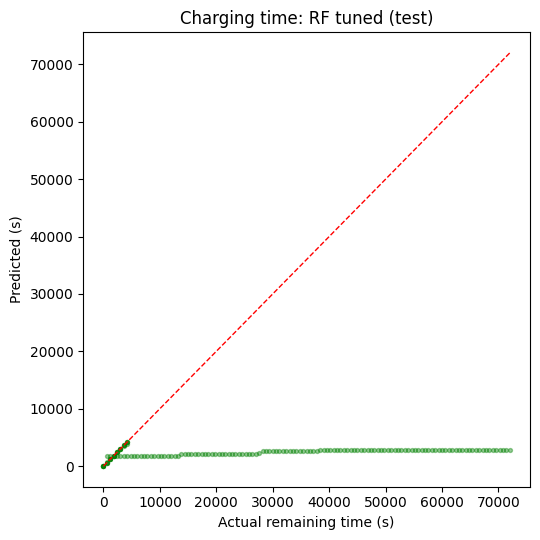

In [9]:
charge_ok, charge_info = False, {}
if not os.path.exists(FULL_PATH):
    print("dataset_v1_full.csv not found - skipping charging-time section.")
else:
    d = pd.read_csv(FULL_PATH)
    d["prog_time_td"] = pd.to_timedelta(d["prog_time"], errors="coerce")
    d = d.sort_values(["file_id", "prog_time_td"]).reset_index(drop=True)
    d["status_change"] = (d["status"] != d["status"].shift(1)) | (d["file_id"] != d["file_id"].shift(1))
    d["segment_id"] = d["status_change"].cumsum()
    dc = d[d["status"] == "CHA"].copy()
    seg_end = dc.groupby("segment_id")["prog_time_td"].transform("max")
    dc[CHARGE_TARGET] = (seg_end - dc["prog_time_td"]).dt.total_seconds()
    dc = dc.dropna(subset=[CHARGE_TARGET] + CHARGE_FEATURES)
    c_tr = dc[dc["file_id"].isin(train_ids)].copy()
    c_te = dc[dc["file_id"].isin(test_ids)].copy()
    print(f"Charging rows -> train {len(c_tr)} ({c_tr['file_id'].nunique()} files) | test {len(c_te)} ({c_te['file_id'].nunique()} files)")

    if c_tr["file_id"].nunique() < 3 or c_te["file_id"].nunique() < 1:
        print("Too few charging files for a reliable grouped study - skipping (state this limitation in the write-up).")
    else:
        charge_ok = True
        g = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        a_idx, b_idx = next(g.split(c_tr, groups=c_tr["file_id"]))
        cf, cv = c_tr.iloc[a_idx], c_tr.iloc[b_idx]
        grid = {"n_estimators": [100, 200, 300], "max_depth": [6, 10, 14]}      # Day 20 grid
        clog = []
        for p in ParameterGrid(grid):
            m = RandomForestRegressor(random_state=SEED, n_jobs=-1, **p).fit(cf[CHARGE_FEATURES], cf[CHARGE_TARGET])
            clog.append({**p, "val_MAE": mean_absolute_error(cv[CHARGE_TARGET], m.predict(cv[CHARGE_FEATURES]))})
        clog = pd.DataFrame(clog).sort_values("val_MAE").reset_index(drop=True)
        charge_best = {k_: int(clog.loc[0, k_]) for k_ in grid}
        clog.to_csv(f"{OUT_DIR}/charging_rf_tuning_log.csv", index=False)
        print("Best validated charging RF config:", charge_best)

        mean_m = DummyRegressor().fit(c_tr[CHARGE_FEATURES], c_tr[CHARGE_TARGET])
        lin_c  = LinearRegression().fit(c_tr[CHARGE_FEATURES], c_tr[CHARGE_TARGET])
        rf_c   = RandomForestRegressor(random_state=SEED, n_jobs=-1, **charge_best).fit(c_tr[CHARGE_FEATURES], c_tr[CHARGE_TARGET])
        yc = c_te[CHARGE_TARGET]
        ctab = pd.DataFrame({"Mean baseline": metrics(yc, mean_m.predict(c_te[CHARGE_FEATURES])),
                             "Linear":        metrics(yc, lin_c.predict(c_te[CHARGE_FEATURES])),
                             "RF tuned":      metrics(yc, rf_c.predict(c_te[CHARGE_FEATURES]))}).T
        ctab["MAE_minutes"] = ctab["MAE"] / 60
        print("\n===== REMAINING CHARGING TIME - TEST (seconds) =====")
        display(ctab.round(3))
        ctab.to_csv(f"{OUT_DIR}/charging_time_results.csv")

        c_te["pred_rf"] = rf_c.predict(c_te[CHARGE_FEATURES])
        c_te["abs_err"] = (c_te[CHARGE_TARGET] - c_te["pred_rf"]).abs()
        cpf = c_te.groupby("file_id")["abs_err"].agg(["size", "mean", "max"]).rename(columns={"size": "n_rows", "mean": "MAE_s", "max": "max_err_s"})
        display(cpf.round(1)); cpf.to_csv(f"{OUT_DIR}/charging_time_per_file.csv")

        plt.figure(figsize=(5.5, 5.5))
        plt.scatter(yc, c_te["pred_rf"], s=8, alpha=.4, color="green")
        lim = [0, max(yc.max(), c_te["pred_rf"].max())]; plt.plot(lim, lim, "r--", lw=1)
        plt.xlabel("Actual remaining time (s)"); plt.ylabel("Predicted (s)"); plt.title("Charging time: RF tuned (test)")
        plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_charging_pred_vs_actual.png", dpi=150); plt.show()
        charge_info = {"best_params": charge_best, "table": ctab, "n_train_files": int(c_tr["file_id"].nunique()),
                       "n_test_files": int(c_te["file_id"].nunique())}

In [11]:
rf, lin, mean_b = results.loc[M_RFT], results.loc[M_LIN], results.loc[M_MEAN]
rf_u, gb = results.loc[M_RFU], results.loc[M_GB]
tuned_gain = 100 * (rf_u["test_MAE"] - rf["test_MAE"]) / rf_u["test_MAE"]


if hybrid_helps:
    direction = ("Week-4 direction: build the final SOC model as a Linear + Random-Forest-residual hybrid on raw features "
                 "(the validation probe beat both parents on RMSE), with predictions clipped to [0,100].")
elif lin["test_RMSE"] < rf["test_RMSE"]:
    direction = ("Week-4 direction: carry both the tuned Random Forest and the plain Linear model into the freeze and decide with "
                 "grouped cross-validation, because Linear has the lower RMSE/higher R2 while RF has the lower MAE.")
else:
    direction = ("Week-4 direction: freeze the tuned Random Forest on raw features for SOC, clipped to [0,100], and "
                 "spend the remaining time on the identified weak regimes.")

charge_txt = "Charging-time study skipped (data file missing or too few charging files)."
if charge_ok:
    ct = charge_info["table"]
    charge_txt = (f"Remaining charging time ({charge_info['n_train_files']} train / {charge_info['n_test_files']} test charge files): "
                  f"mean baseline MAE={ct.loc['Mean baseline','MAE']:.0f}s, tuned RF MAE={ct.loc['RF tuned','MAE']:.0f}s "
                  f"({ct.loc['RF tuned','MAE']/60:.1f} min), R2={ct.loc['RF tuned','R2']:.3f}. "
                  f"The signal is sparse and repetitive (CC-CV), so this target stays the weakest and is judged separately from SOC.")

eng_txt = "Engineered-feature diagnostics not run."
if eng_summary:
    e = eng_summary["Linear (engineered)"]
    eng_txt = (f"Engineered features still underperform: Linear MAE={e['MAE']:.2f}, R2={e['R2']:.3f} "
               f"({int(eng_diag['corr_sign_flip'].sum())} of {len(eng_diag)} features flip correlation sign between train and test files). "
               f"They are excluded from the final candidate until the feature pipeline is audited.")

submission = f"""

1) BASELINE vs TUNED (SOC %, frozen test split, scored once)
- Mean baseline : MAE {mean_b['test_MAE']:.2f} | RMSE {mean_b['test_RMSE']:.2f} | R2 {mean_b['test_R2']:.3f}
- Linear (raw)  : MAE {lin['test_MAE']:.2f} | RMSE {lin['test_RMSE']:.2f} | R2 {lin['test_R2']:.3f}
- RF untuned    : MAE {rf_u['test_MAE']:.2f} | RMSE {rf_u['test_RMSE']:.2f} | R2 {rf_u['test_R2']:.3f}
- RF tuned {best_params}: MAE {rf['test_MAE']:.2f} | RMSE {rf['test_RMSE']:.2f} | R2 {rf['test_R2']:.3f}
- Gradient Boosting (raw): MAE {gb['test_MAE']:.2f} | RMSE {gb['test_RMSE']:.2f} | R2 {gb['test_R2']:.3f}
Tuning changed RF test MAE by {tuned_gain:+.1f}% vs the untuned Day-16 config. Tuning used a grouped validation split from the training files only.

2) PROJECT-SPECIFIC STUDY
- Error by regime (tuned RF): worst SOC band = {worst_soc_band} (MAE {by_soc['MAE_RF'].max():.2f}); worst ambient temperature = {worst_temp} C (MAE {by_temp['MAE_RF'].max():.2f}).
- Rows whose inputs fall outside the training 1-99 percentile range: RF MAE {ood_tab['MAE_RF'].get(True, float('nan')):.2f} vs {ood_tab['MAE_RF'].get(False, float('nan')):.2f} inside the range.
- {eng_txt}
- {charge_txt}

3) SUCCESSES AND FAILURES
- Best files (lowest RF MAE): {', '.join(best_files)}.
- Worst files: {', '.join(worst_files)}. See fig_success_failure_traces.png.

4) REMAINING WEAKNESSES / UNUSUAL ERRORS
- RMSE/MAE ratio of RF = {rf['RMSE/MAE']:.2f}; the top 1% of rows carry {100*top1_share:.0f}% of RF squared error and the single worst file ({worst_file}) carries {100*worst_file_share:.0f}%. Errors are rare but large, not uniform.
- {imp} RF predictions fall outside the physical 0-100% range (clipping is a free fix).
- Engineered features are unreliable (see above); charging time is data-starved.

5) PROPOSED WEEK-4 DIRECTION (for mentor approval)
- {direction}
- Freeze preprocessing, the grouped split and the MAE/RMSE/R2 protocol on Day 22; choose the final model with grouped cross-validation on training files only, using a pre-agreed rule that rewards robustness and simplicity.
- Audit the Day-13 engineered features before any further use.
- Keep charging-time as a separately-judged, lower-confidence deliverable.

QUESTIONS FOR MENTOR: (a) Do you approve the direction above? (b) Is a Linear-vs-tree decision by cross-validated RMSE + MAE acceptable? (c) Should engineered features be dropped from the final model?
"""
print(submission)
with open(f"{OUT_DIR}/day21_written_submission.txt", "w") as f:
    f.write(submission)

handoff = {
    "created": str(datetime.datetime.now()),
    "soc_rf_best_params": best_params,
    "charging_rf_best_params": charge_info.get("best_params"),
    "test_metrics": {k_: {m_: float(v_) for m_, v_ in results.loc[k_, ["test_MAE", "test_RMSE", "test_R2"]].items()} for k_ in results.index},
    "hybrid_helps_on_validation": bool(hybrid_helps),
    "direction": direction,
}
with open(f"{OUT_DIR}/day21_handoff.json", "w") as f:
    json.dump(handoff, f, indent=2)
print("\nSaved to", OUT_DIR)
for fn in sorted(os.listdir(OUT_DIR)): print(" -", fn)



1) BASELINE vs TUNED (SOC %, frozen test split, scored once)
- Mean baseline : MAE 28.93 | RMSE 32.19 | R2 -0.033
- Linear (raw)  : MAE 18.55 | RMSE 25.20 | R2 0.367
- RF untuned    : MAE 27.33 | RMSE 37.72 | R2 -0.418
- RF tuned {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 2}: MAE 27.41 | RMSE 37.85 | R2 -0.428
- Gradient Boosting (raw): MAE 25.85 | RMSE 36.98 | R2 -0.363
Tuning changed RF test MAE by -0.3% vs the untuned Day-16 config. Tuning used a grouped validation split from the training files only.

2) PROJECT-SPECIFIC STUDY
- Error by regime (tuned RF): worst SOC band = 0-15 (knee) (MAE 71.64); worst ambient temperature = 25 C (MAE 27.41).
- Rows whose inputs fall outside the training 1-99 percentile range: RF MAE 38.32 vs 26.47 inside the range.
- Engineered-feature diagnostics not run.
- Remaining charging time (9 train / 5 test charge files): mean baseline MAE=27124s, tuned RF MAE=26626s (443.8 min), R2=-1.285. The signal is sparse and repetitive (CC-CV), so 